# Analyse des résultats — *La Liberté*, split test

Ce carnet **lit** ce que la chaîne a produit (`finlam-prod evaluate` → `results/*_pages.csv`,
`finlam-prod train` → `models/la_liberte/`) et le met en images. Il n'entraîne rien et ne recalcule
aucune métrique : tout vient de `finlam_prod.evaluation`. Question à laquelle il répond : **où et
pourquoi la doublure se trompe-t-elle**, et qu'est-ce que cela impose au contrôle qualité ?

Prérequis (voir README) :

```bash
finlam-prod download --dataset la-liberte --split test                 # annotations, 433 pages
finlam-prod download --dataset la-liberte --split test --images --limit 40   # 40 images pour la partie 3
finlam-prod train --dataset la-liberte --split validation --models-dir models/la_liberte
finlam-prod evaluate --dataset la-liberte --split test                  # règles
finlam-prod evaluate --dataset la-liberte --split test --models-dir models/la_liberte   # doublure
```

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from finlam_prod.data.schema import load_pages
from finlam_prod.evaluation import viz
from finlam_prod.evaluation.finlam import bootstrap_ci
from finlam_prod.pipeline.ml import BoundarySegmenter, GradientBoostingZoneClassifier
from finlam_prod.pipeline.run import Pipeline

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CACHE, RESULTS, MODELS = ROOT / "data/cache", ROOT / "results", ROOT / "models/la_liberte"
plt.rcParams["figure.dpi"] = 110

full = CACHE / "la_liberte_test.jsonl"
pages = load_pages(full if full.exists() else CACHE / "la_liberte_test_n40.jsonl")
image_of = {p.id: CACHE / "images_la_liberte" / f"{p.id}.jpg" for p in pages}
print(f"{len(pages)} pages, {sum(image_of[p.id].exists() for p in pages)} avec image")

433 pages, 40 avec image


## 1. Les métriques, avec leurs intervalles

Une ligne par page dans `results/eval_la_liberte_test_<système>_pages.csv`. La moyenne et l'IC95 %
(bootstrap sur les pages, comme HIPE-OCRepair 2026) sont recalculés ici par `bootstrap_ci` pour
montrer que la table du README se reproduit.

In [2]:
tables = viz.load_per_page(RESULTS, "la_liberte_test")
metrics = ["as_f1", "as_miou", "jaccard_article", "bleu_block", "pairwise_f1", "zone_accuracy"]
summary = {}
for system, table in tables.items():
    ci = bootstrap_ci(table[metrics].to_dict("records"), n_boot=500, seed=0)
    summary[system] = {m: "{:.3f} [{:.3f} ; {:.3f}]".format(*ci[m]) for m in metrics}
pd.DataFrame(summary)

,doublure,regles
as_f1,0.424 [0.409 ; 0.438],0.264 [0.250 ; 0.276]
as_miou,0.808 [0.797 ; 0.818],0.742 [0.730 ; 0.752]
jaccard_article,0.784 [0.768 ; 0.799],0.716 [0.696 ; 0.734]
bleu_block,0.625 [0.612 ; 0.638],0.625 [0.612 ; 0.638]
pairwise_f1,0.585 [0.570 ; 0.598],0.471 [0.457 ; 0.488]
zone_accuracy,0.938 [0.936 ; 0.941],0.626 [0.617 ; 0.634]


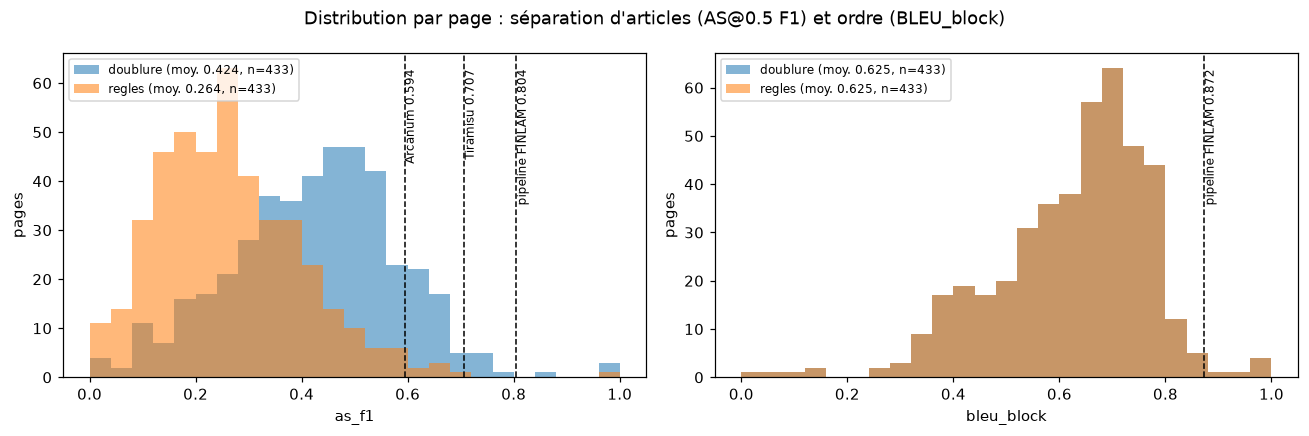

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
viz.plot_metric_distribution(tables, "as_f1", ax=axes[0])
viz.plot_metric_distribution(tables, "bleu_block", ax=axes[1])
fig.suptitle("Distribution par page : séparation d'articles (AS@0.5 F1) et ordre (BLEU_block)")
fig.tight_layout()

Lecture : la doublure déplace toute la distribution d'AS F1 vers la droite mais reste loin des
0,80 du pipeline du consortium ; sur l'ordre les deux systèmes sont confondus (même ordonnanceur
XY guidé par les colonnes), la référence à 0,87 est ce que LayoutReader apporte.

## 2. Où sont les erreurs

Deux angles : la confusion entre classes de zones (le boosting), et la dépendance du F1 à la densité
de la page (le regroupeur).

,HEADER_TITLE,HEADER_TEXT,ARTICLE_ILLUSTRATION,ARTICLE_TITLE,ARTICLE_TEXT,ARTICLE_SUBTITLE,ARTICLE_INSIDEHEADING,ARTICLE_TABLE
HEADER_TITLE,21,0,0,0,0,0,0,0
HEADER_TEXT,0,130,0,1,29,0,0,2
ARTICLE_ILLUSTRATION,2,0,258,1,0,0,0,0
ARTICLE_TITLE,0,8,2,1627,289,57,66,1
ARTICLE_TEXT,0,21,0,197,20752,7,74,33
ARTICLE_SUBTITLE,0,2,0,111,161,203,59,4
ARTICLE_INSIDEHEADING,0,1,0,97,210,43,296,1
ARTICLE_TABLE,0,0,0,9,0,1,0,27


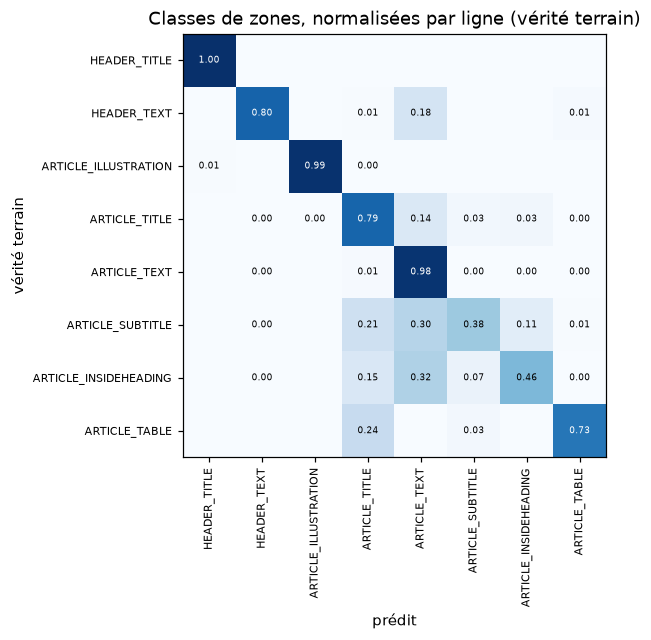

In [4]:
pipeline = Pipeline(
    GradientBoostingZoneClassifier.load(MODELS / "zone_classifier.joblib"),
    segmenter=BoundarySegmenter.load(MODELS / "segmenter.joblib"),
)
sample = pages[:120]  # suffisant pour la confusion ; ~10 s
predicted = [pipeline.run(p) for p in sample]
confusion = viz.confusion_table(sample, predicted)
fig, ax = plt.subplots(figsize=(6, 5))
viz.plot_confusion(confusion, ax=ax)
ax.set_title("Classes de zones, normalisées par ligne (vérité terrain)")
confusion

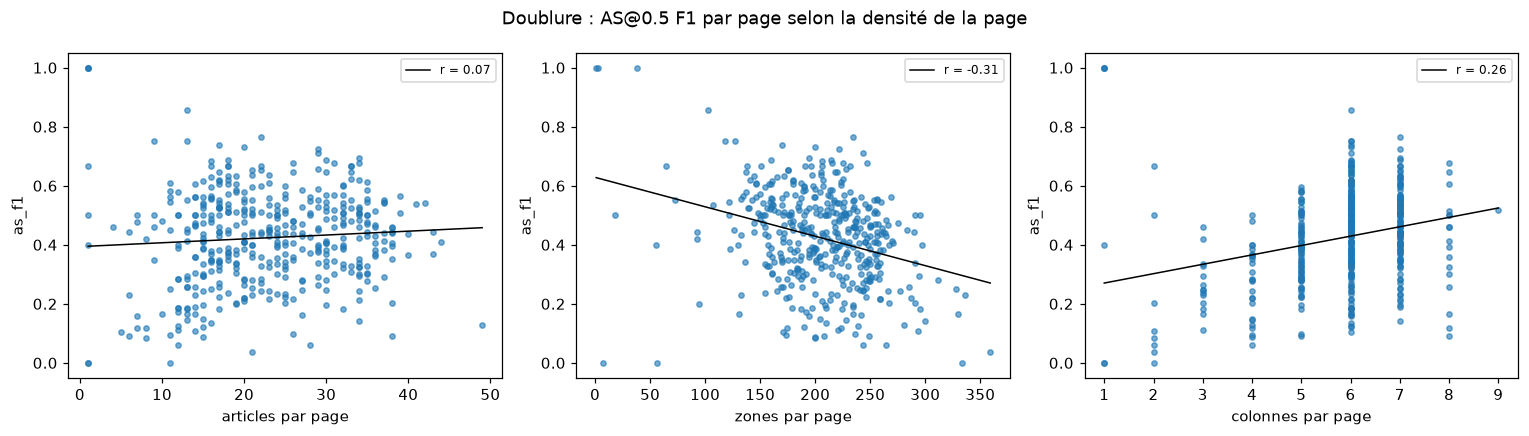

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, by in zip(axes, ["articles", "zones", "colonnes"]):
    viz.plot_metric_by(tables["doublure"], pages, "as_f1", by, ax=ax)
fig.suptitle("Doublure : AS@0.5 F1 par page selon la densité de la page")
fig.tight_layout()

In [6]:
worst = tables["doublure"].nsmallest(10, "as_f1")[["page_id", "as_f1", "jaccard_article", "zone_accuracy"]]
worst

,page_id,as_f1,jaccard_article,zone_accuracy
164,027a7bd8-856f-4d37-9161-0a06cd5da79c,0.000000,0.407407,0.942943
351,1fca7a5e-143a-4890-8bef-555bc7363e5a,0.000000,0.333333,1.000000
400,b4405b0e-9abb-46b8-9118-dc09965d823f,0.000000,0.250000,0.857143
154,10e22d07-f364-4c05-8d0c-5b659f70d0a7,0.036364,0.617647,0.944290
115,00d3b0e4-70c6-488e-8ace-809ce998cb39,0.060606,0.736842,0.939394
430,81bb2c39-8ead-4187-8b63-d9b1cf263fc2,0.060606,0.571429,0.983539
147,2fc0d97e-799c-4161-9aa0-86f1301c3c8f,0.083333,0.500000,0.990000
43,0ffdb2e9-9668-477a-976b-6b3ba5c63b36,0.088889,0.500000,0.925000
166,e18c11bd-f6ba-423f-bfe0-bf2d54ad3150,0.090909,0.375000,0.975962
230,3ad2ddda-6379-4aba-bc6a-4eef788dbbb5,0.090909,0.736842,0.967871


## 3. Regarder les pages

Vérité terrain à gauche, prédiction à droite, une couleur par article (gris : hors article).
Les trois pages : la meilleure, la médiane et la pire parmi celles dont on a l'image.

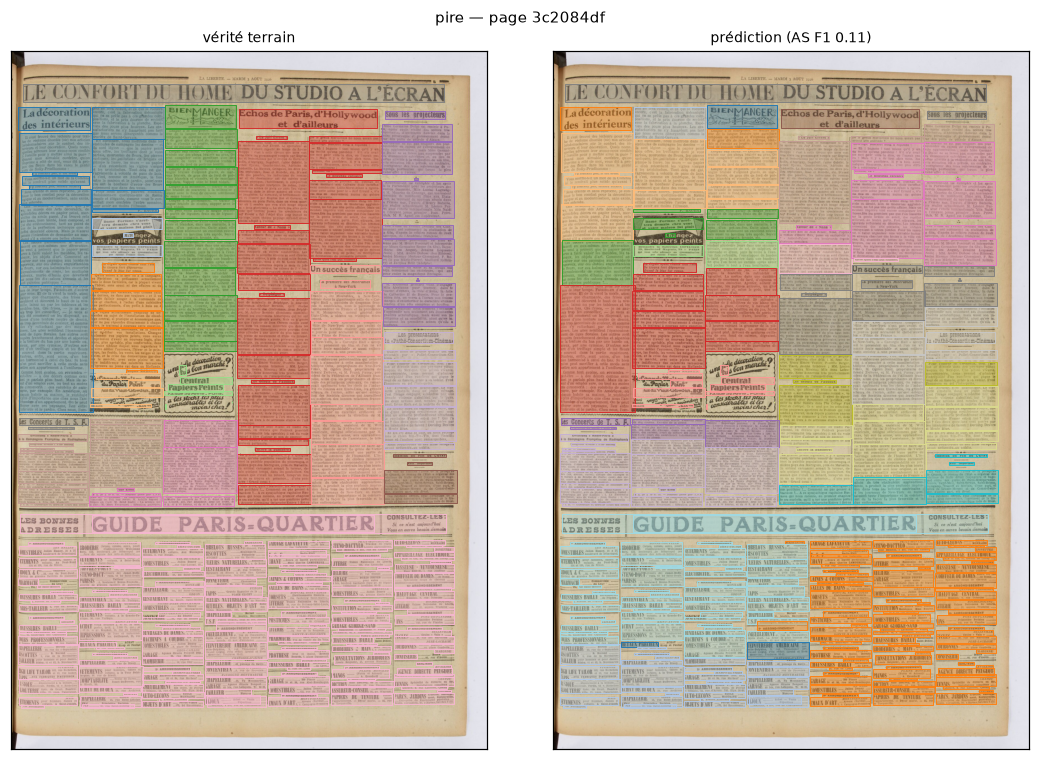

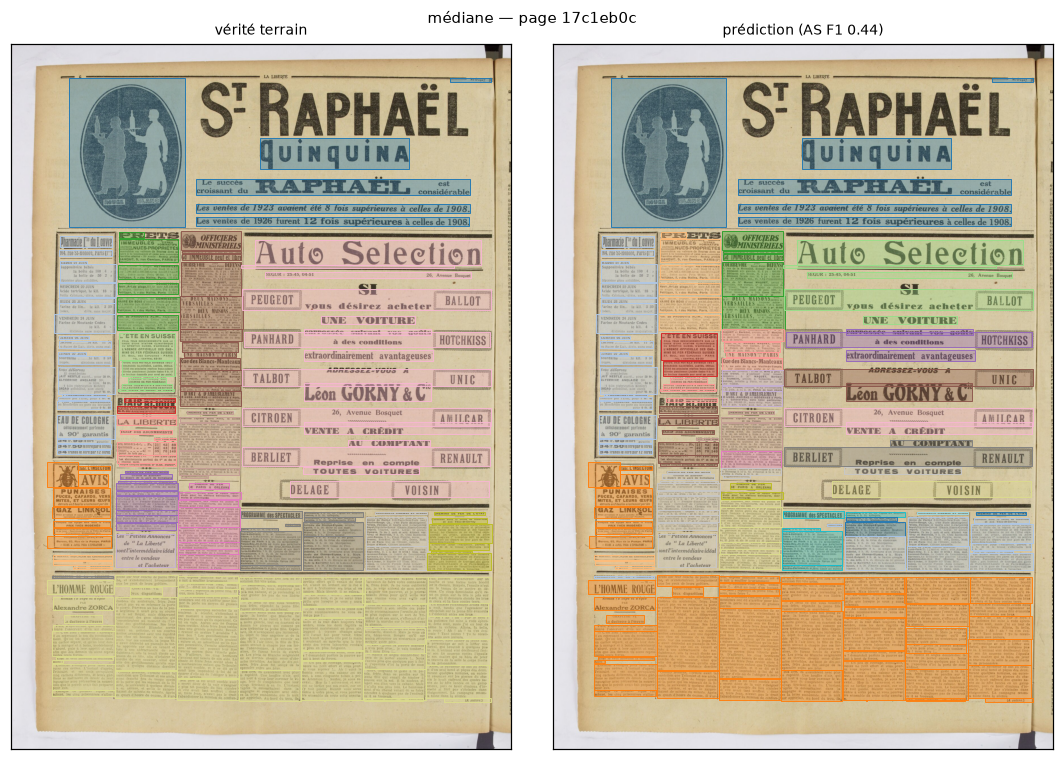

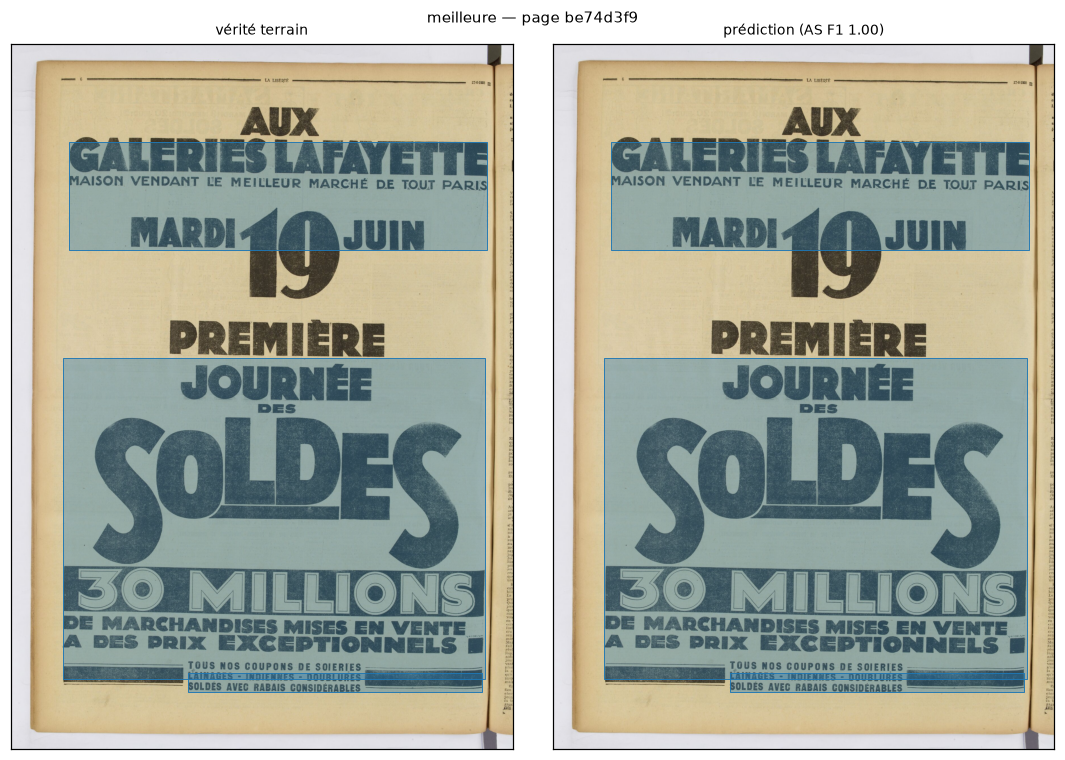

In [7]:
scores = tables["doublure"].set_index("page_id")["as_f1"]
with_image = [p for p in pages if image_of[p.id].exists() and p.id in scores.index]
ranked = sorted(with_image, key=lambda p: scores[p.id])
picks = {"pire": ranked[0], "médiane": ranked[len(ranked) // 2], "meilleure": ranked[-1]}
for label, page in picks.items():
    fig = viz.compare_page(page, pipeline.run(page), image_of[page.id], scores[page.id])
    fig.suptitle(f"{label} — page {page.id[:8]}", fontsize=10)

## 4. Ce qu'on en tire (433 pages)

1. **L'erreur dominante est la sur-segmentation, et c'est en partie une convention d'annotation.**
   Précision AS 0,40 < rappel 0,47 : la doublure prédit plus d'articles qu'il n'y en a. Les pires
   pages (AS F1 = 0 avec exactitude de classes 0,86-1,00) sont celles où la vérité terrain regroupe
   une **rubrique entière** en un seul article — « Échos de Paris » sur deux colonnes, le « Guide
   Paris-Quartier » (une page de petites annonces = un article), un feuilleton — alors que la doublure
   ouvre un article à chaque titre. Sur ces pages la classification est juste et le regroupement est
   faux : le modèle ne manque pas d'yeux, il lui manque la règle. **Question au consortium** : qu'est-ce
   qui ferme un article — un titre, ou un changement de rubrique (`zone_section_ids`) ?
2. **Les confusions restantes sont exactement celles qui décident des frontières.** TEXT est reconnu à
   98 %, mais TITLE à 79 % (14 % pris pour du texte), SUBTITLE à 38 % (21 % pris pour un titre,
   30 % pour du texte) et INSIDEHEADING à 46 %. Un sous-titre pris pour un titre ouvre un faux article ;
   un titre pris pour du texte en fusionne deux. Les 94 % d'exactitude sont portés par TEXT (84 % des
   zones) : la métrique à suivre est le F1 macro (0,67), pas l'exactitude.
3. **La densité qui compte, c'est le nombre de lignes, pas d'articles.** AS F1 par page : r = −0,31
   avec le nombre de zones, r = 0,07 avec le nombre d'articles, r = +0,26 avec le nombre de colonnes
   (les pages à 1-3 colonnes sont des pages spéciales : publicités, guides, pleine page). Règle de QC
   dérivée, sans vérité terrain : **page au-delà de ~280 zones ou à moins de 4 colonnes → relecture**,
   seuils à calibrer sur le 90ᵉ centile de ce jeu.
4. **Ce que ça change pour l'industrialisation.** Rien de tout cela ne se corrige en améliorant la
   doublure : la sur-segmentation demande l'information de rubrique et de continuation que seul un
   modèle avec le texte et l'image apporte — c'est précisément ce que le pipeline du consortium
   (LayoutReader + regroupeur) gagne, +38 points. En revanche la règle de QC du point 3 et la
   convention du point 1 s'appliquent **à ses sorties aussi**, et c'est là que ce carnet sert.